# Proyecto de Machine Learning: Predicción de Churn en Telecomunicaciones (Telco)
**Asignatura:** Modelos y Simulación de Sistemas I  
Inteligencia Artificial para las Ciencias e Ingenierías  

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/CaroGomezO/telco-customer-churn-prediction/blob/main/fase-1/Telco_Customer_Churn_Pipeline_Completo.ipynb)


# 6.1. Introducción

## Problema seleccionado:
**Churn o pérdida de clientes en empresas de telecomunicaciones**:

El churn o pérdida de clientes es un problema crítico para la industria de telecomunicaciones. Cada cliente que se va representa ingresos recurrentes perdidos y un costo de reemplazo que suele ser mayor que el de simplemente retenerlo. En mercados con millones de usuarios reducir la tasa de abandono incluso en un 1% puede traducirse en ganancias significativas.

Predecir qué clientes tienen mayor riesgo de irse permite a un operador priorizar acciones de retención como ofertas, programas de fidelización y mejoras del servicio. Este proyecto aborda esa tarea con un conjunto de datos público de ejemplo y, lo que realmente se puede predecir con él, se explica en la sección "Alcance y limitaciones de los resultados".


## Objetivo del modelo:
**Predecir el comportamiento para retener a los clientes**:

El objetivo es construir un modelo que prediga si un cliente cancelará el servicio, de modo que, a partir de sus características, la empresa pueda dirigir acciones de retención antes de que el cliente se vaya. El trabajo tiene fines académicos, ya que el énfasis está en el proceso (preparación sin fuga de información, validación, evaluación y reproducibilidad).


## Tipo de problema:
**Clasificación binaria**:

Aprendizaje supervisado de clasificación binaria. Se busca predecir si un cliente abandona el servicio (Churn = Sí/1) o no (Churn = No/0). No es un problema de regresión porque la salida es categórica. Se puede usar un modelo como regresión logística para estimar la probabilidad de churn y, mediante un umbral, convertir esa probabilidad en una clase.

## Variable objetivo:
**Churn**

Churn (Yes/No o 1/0). Es una variable categórica binaria que indica si el cliente canceló el servicio o no.

## Fuente de los datos:

El dataset utilizado es Telco Customer Churn, publicado originalmente por IBM como parte de sus Sample Data Sets. Contiene información de 7043 clientes de una empresa ficticia de telecomunicaciones en California durante el tercer trimestre (Q3). Incluye variables demográficas, servicios contratados, tipo de contrato, forma de pago, facturación y la variable objetivo Churn.

Enlace del dataset:
[Telco Customer Churn: IBM / Kaggle](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data)

## Alcance y limitaciones de los resultados
- **Los datos son de una empresa ficticia.** IBM publicó este conjunto como dato de ejemplo para sus herramientas de analítica pues describe a una compañía de telecomunicaciones **inventada** (7043 clientes en California durante un trimestre). No son clientes reales de ninguna empresa.
- **Los resultados no son evidencia sobre clientes reales de operadores colombianos ni de ningún otro operador real.** Al ser datos de ficticios, los patrones que aprende el modelo, por ejemplo, que el contrato mes a mes se asocie con más abandono, son propios de este conjunto de ejemplo y podrían no cumplirse en otro mercado u otra empresa.
- **El valor del trabajo es metodológico.** Muestra cómo construir, validar y documentar un modelo de clasificación de forma reproducible. Para usarlo con un operador real habría que reentrenarlo y validarlo con datos propios de ese operador.

## Momento de observación
- **Momento de observación:** el conjunto de datos representa un corte transversal. Cada fila describe a un cliente con los servicios, el contrato y la facturación que tenía en el momento del corte, es decir, el trimestre de la empresa ficticia. No hay historial de cada cliente en el tiempo.
- **Consecuencia:** con estos datos el modelo *clasifica* clientes a partir de su perfil en el corte transversal, por lo que no se puede verificar que prediga el futuro. Para un uso real habría que construir las variables en un momento *t* y la etiqueta en una ventana posterior definida (por ejemplo, los 30 días siguientes), sin usar información posterior a *t*.


# 6.2. Descripción del Conjunto de Datos

**Número de observaciones**: 7043
**Número de variables**: 21

| # | Variable | Tipo de variable | Descripción | Rango de valores |
| :-: | :--- | :--- | :--- | :--- |
| 1 | **customerID** | Identificador | Código alfanumérico único asignado a cada usuario | 7,043 valores únicos (ej. `7590-VHVEG`) |
| 2 | **gender** | Categórica nominal | Género del cliente | `Female`, `Male` |
| 3 | **SeniorCitizen** | Categórica binaria | Indica si el cliente es una persona de la tercera edad | `0` (No), `1` (Sí) |
| 4 | **Partner** | Categórica binaria | Indica si el cliente está casado o tiene pareja | `Yes`, `No` |
| 5 | **Dependents** | Categórica binaria | Indica si el cliente vive con personas que dependen económicamente de él | `Yes`, `No` |
| 6 | **tenure** | Numérica discreta | Número de meses que el cliente lleva suscrito a la compañía | Entero entre `0` y `72` meses |
| 7 | **PhoneService** | Categórica binaria | Indica si el cliente tiene contratado el servicio de telefonía fija | `Yes`, `No` |
| 8 | **MultipleLines** | Categórica nominal | Indica si el cliente cuenta con varias líneas telefónicas | `No`, `Yes`, `No phone service` |
| 9 | **InternetService** | Categórica nominal | Tipo de conexión o tecnología de internet contratada | `DSL`, `Fiber optic`, `No` |
| 10 | **OnlineSecurity** | Categórica nominal | Servicio adicional de seguridad y antivirus en línea | `No`, `Yes`, `No internet service` |
| 11 | **OnlineBackup** | Categórica nominal | Servicio de copia de seguridad / almacenamiento en la nube | `Yes`, `No`, `No internet service` |
| 12 | **DeviceProtection** | Categórica nominal | Plan de garantía o cobertura ante daños del equipo | `No`, `Yes`, `No internet service` |
| 13 | **TechSupport** | Categórica nominal | Soporte técnico prioritario y especializado contratado | `No`, `Yes`, `No internet service` |
| 14 | **StreamingTV** | Categórica nominal | Acceso a canales de televisión por suscripción vía streaming | `No`, `Yes`, `No internet service` |
| 15 | **StreamingMovies** | Categórica nominal | Acceso a catálogo de películas por streaming | `No`, `Yes`, `No internet service` |
| 16 | **Contract** | Categórica nominal | Plazo del contrato y periodicidad de facturación | `Month-to-month`, `One year`, `Two year` |
| 17 | **PaperlessBilling** | Categórica binaria | Modalidad de recepción de factura electrónica sin papel | `Yes`, `No` |
| 18 | **PaymentMethod** | Categórica nominal | Medio o método elegido por el usuario para abonar su factura | `Electronic check`, `Mailed check`, `Bank transfer (automatic)`, `Credit card (automatic)` |
| 19 | **MonthlyCharges** | Numérica continua | Monto cobrado periódicamente de manera mensual al cliente | Decimal entre `18.25` y `118.75` USD |
| 20 | **TotalCharges** | Numérica continua | Monto total acumulado facturado al cliente durante toda su antigüedad | Decimal entre `18.80` y `8684.80` USD |
| 21 | **Churn** | Categórica binaria | **Variable objetivo**: Indica si el cliente abandonó la empresa en el último mes | `No` (73.46%), `Yes` (26.54%) |


#### Variable objetivo:
**Churn**: Es una variable categórica binaria que indica si el cliente canceló el servicio o no.

### Tipos de variables:
  * *Demográficas:* `gender`, `SeniorCitizen`, `Partner`, `Dependents`.
  * *Servicios contratados:* `PhoneService`, `MultipleLines`, `InternetService`, `OnlineSecurity`, `OnlineBackup`, `DeviceProtection`, `TechSupport`, `StreamingTV`, `StreamingMovies`.
  * *Información de la cuenta y contrato:* `tenure` (antigüedad en meses), `Contract`, `PaperlessBilling`, `PaymentMethod`, `MonthlyCharges`, `TotalCharges`.


### Posibles limitaciones del conjunto de datos:

* **Predominancia de variables categóricas:** 16 de las 20 características son de naturaleza cualitativa, lo que obliga a emplear codificaciones numéricas (como *One-Hot Encoding*) antes de entrenar algoritmos que calculan distancias o multiplicaciones de matrices.
* **Disparidad de escalas en variables numéricas:** `tenure` (0 a 72 meses) y `MonthlyCharges` (18.25 a 118.75 USD) operan en rangos y unidades numéricas muy distintas, requiriendo estandarización para modelos paramétricos como la Regresión Logística.
* **Columna identificadora no predictiva:** `customerID` es una clave primaria interna sin poder predictivo que únicamente añade dimensionalidad espuria y debe eliminarse.
* **Espacios en blanco en `TotalCharges`:** Existen 11 registros donde esta variable es un espacio en blanco (`" "`) debido a que son clientes recién dados de alta con `tenure = 0`, lo que requiere un tratamiento explícito de imputación o eliminación justificada.
* **Falta de métricas de telemetría dinámica:** No se dispone de variables temporales recientes como cantidad de llamadas a soporte técnico el último mes, quejas interpuestas o caídas de señal, que son predictores críticos en escenarios reales.
* **Desbalance de clases:** ~26.5% abandono vs. 73.5% retención.
* **Datos de una empresa ficticia:** el conjunto es un ejemplo publicado por IBM, por lo que no representa clientes reales y sus resultados no deben presentarse como evidencia sobre operadores reales.



### Configuración del Entorno e Importaciones
Se fija la semilla aleatoria (`RANDOM_STATE = 42`) para garantizar **reproducibilidad total**.



In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display
from itertools import combinations

from scipy.stats import chi2_contingency
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.tools import add_constant

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.dummy import DummyClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier
from xgboost import XGBClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay, PrecisionRecallDisplay,
    classification_report, average_precision_score
)

# Configuración visual y semilla global
sns.set_theme(style="whitegrid")
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)


### Explicación de los Import's


#### 1. Manipulación de Datos y Computación Numérica
* **`numpy` (`np`):** Librería fundamental para computación científica en Python. Proporciona estructuras de arreglos multidimensionales de alto rendimiento y funciones matemáticas vectorizadas. Casi todas las librerías de ML la utilizan por debajo.
* **`pandas` (`pd`):** Permite manipular y analizar datos estructurados en formato de tabla (*DataFrames*). Se utiliza para cargar los datos crudos, realizar agregaciones, filtrados, estadísticas y estructurar los conjuntos de entrenamiento y prueba.
* **`display` (`IPython.display`):** Función de IPython que permite renderizar tablas y objetos de forma estética y formateada en las celdas de salida del notebook.

#### 2. Visualización de Datos
* **`matplotlib.pyplot` (`plt`):** Librería base para la generación de gráficos en 2D en Python (figuras, ejes, curvas y personalización de títulos y escalas).
* **`seaborn` (`sns`):** Librería de visualización construida sobre `matplotlib`. Ofrece una interfaz de alto nivel para trazar gráficos estadísticos atractivos (como mapas de calor de correlación y diagramas de barras).

#### 3. Análisis Estadístico y Diagnóstico de Variables
* **`chi2_contingency` (`scipy.stats`):** Realiza la prueba de independencia de Chi-cuadrado ($\chi^2$) sobre tablas de contingencia. Sirve para evaluar si existe una relación estadísticamente significativa entre cada variable categórica y la variable objetivo `Churn`.
* **`variance_inflation_factor` (VIF) y `add_constant` (`statsmodels`):** 
  * `add_constant`: Añade la columna de intercepto requerida por los modelos lineales de regresión.
  * `variance_inflation_factor`: Cuantifica la **multicolinealidad** entre las variables numéricas (`tenure`, `MonthlyCharges`, `TotalCharges`). Un VIF elevado (> 5 o 10) indica redundancia severa y justifica la eliminación de variables.

#### 4. Preprocesamiento y Partición de Datos
* **`train_test_split` (`sklearn.model_selection`):** Divide el conjunto de datos en subconjuntos de entrenamiento (80%) y prueba (20%), permitiendo aplicar **estratificación** (`stratify=y`) para preservar la proporción original de clientes que desertaron.
* **`StandardScaler` (`sklearn.preprocessing`):** Estandariza las variables numéricas restando la media y dividiendo por la desviación estándar ($\mu=0, \sigma=1$). Es crucial ajustarlo (`.fit()`) solo en el conjunto de entrenamiento para evitar **fuga de información** (*data leakage*).
* **`OneHotEncoder` (`sklearn.preprocessing`):** Convierte variables categóricas (como tipo de contrato o servicio de internet) en variables binarias dummy (0 o 1). Con el parámetro `handle_unknown='ignore'`, gestiona de forma robusta categorías no vistas en inferencia sin descartar información.

#### 5. Algoritmos de Modelado
* **`DummyClassifier` (`sklearn.dummy`):** Clasificador de referencia (*baseline*). No aprende patrones reales de los datos, sino que aplica reglas simples (como predecir siempre la clase mayoritaria). Sirve como umbral mínimo de comparación.
* **`LogisticRegression` (`sklearn.linear_model`):** Modelo lineal clásico para clasificación binaria. Modela la probabilidad logística de pertenencia a una clase; es rápido, interpretable y sirve como referencia lineal fuerte.
* **`RandomForestClassifier` (`sklearn.ensemble`):** Ensamble de árboles de decisión basado en *Bagging* (muestreo con reemplazo) y selección aleatoria de características. Reduce la varianza y el sobreajuste.
* **`GradientBoostingClassifier` (`sklearn.ensemble`):** Ensamble basado en *Boosting*. Construye árboles secuencialmente de forma que cada nuevo árbol corrige los errores residuales del anterior.
* **`XGBClassifier` (`xgboost`):** Implementación de Gradient Boosting optimizada en velocidad y memoria, con regularizaciones $L_1$ y $L_2$ incorporadas para controlar el sobreajuste. Muy popular por su alto desempeño en datos tabulares.

#### 6. Validación Cruzada y Optimización
* **`StratifiedKFold` (`sklearn.model_selection`):** Generador de validación cruzada en $K$ pliegues (*folds*) que asegura que cada partición contenga exactamente la misma proporción de clases que el conjunto completo.
* **`cross_validate` (`sklearn.model_selection`):** Evalúa múltiples métricas simultáneamente en cada iteración de la validación cruzada.
* **`GridSearchCV` (`sklearn.model_selection`):** Realiza una búsqueda exhaustiva sobre una cuadrícula de combinaciones de hiperparámetros para encontrar la configuración óptima del modelo basada en una métrica (en nuestro caso, `f1`).

#### 7. Métricas de Evaluación
* **`accuracy_score`:** Porcentaje de aciertos globales. En clases desbalanceadas puede resultar engañoso.
* **`precision_score`:** De todos los clientes predichos como Churn, cuántos realmente lo eran (evita falsas alarmas).
* **`recall_score` (Sensibilidad):** De todos los clientes que realmente se fueron, cuántos logró detectar el modelo (métrica crítica para no dejar escapar clientes en riesgo).
* **`f1_score`:** Media armónica entre Precisión y Recall. Es la métrica rectora para comparar modelos cuando las clases están desbalanceadas.
* **`roc_auc_score`:** Área bajo la curva ROC. Mide la capacidad del modelo para distinguir entre ambas clases a lo largo de todos los umbrales de decisión posibles.
* **`confusion_matrix` y `ConfusionMatrixDisplay`:** Calcula y grafica la matriz de confusión (Verdaderos Positivos, Falsos Positivos, Verdaderos Negativos, Falsos Negativos).
* **`RocCurveDisplay` y `PrecisionRecallDisplay`:** Grafican de forma directa las curvas ROC y Precision-Recall.
* **`classification_report`:** Resumen tabular que muestra Precision, Recall, F1 y soporte para ambas clases simultáneamente.

#### 8. Persistencia y Almacenamiento
* **`joblib`:** Herramienta de serialización en disco optimizada para estructuras de datos de Python que contienen arreglos grandes de NumPy y estimadores de Scikit-Learn. Permite guardar el modelo entrenado (`joblib.dump`) y cargarlo posteriormente (`joblib.load`) para su reutilización en producción.

# 6.3. Exploración de los Datos (EDA)

Cargamos el archivo original `DatosCrudos.csv` y realizamos un análisis exploratorio detallado:
1. Dimensiones y tipos de datos.
2. Identificación y cuantificación de valores faltantes.
3. Separación en entrenamiento y prueba antes de explorar cualquier relación con la variable objetivo.
4. Estadísticas descriptivas de variables numéricas y categóricas (solo entrenamiento).
5. Distribución de la variable objetivo (`Churn`) (solo entrenamiento).
6. Análisis de relaciones con Churn (Chi-cuadrado para categóricas, Pearson/Spearman para numéricas) (solo entrenamiento).
7. Detección de multicolinealidad (VIF) (solo entrenamiento).

**Importante:** todo análisis que use la variable objetivo, y toda decisión sobre qué variables conservar, se hace únicamente con los datos de entrenamiento. El conjunto de prueba no se explora hasta la evaluación final.



In [2]:
# Carga de datos original (compatible con entorno local y Google Colab)
try:
    df_crudo = pd.read_csv("DatosCrudos.csv")
except FileNotFoundError:
    url_remota = "https://raw.githubusercontent.com/CaroGomezO/telco-customer-churn-prediction/main/fase-1/DatosCrudos.csv"
    print(f"Archivo local no encontrado. Descargando directamente desde GitHub: {url_remota}")
    df_crudo = pd.read_csv(url_remota)

print(f"Dimensiones del dataset original: {df_crudo.shape[0]} filas, {df_crudo.shape[1]} columnas")
df_crudo.head()


Dimensiones del dataset original: 7043 filas, 21 columnas


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [3]:
df_crudo.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

### Dimensiones del conjunto de datos
El conjunto de datos está conformado de 7043 filas incluyendo la primera fila de cabezales y 21 columnas incluyendo la variable objetivo.

### **Tipos de variables**:
| Numeros Enteros (`int64`) | Numeros Decimales (`float64`) | Cadena de Texto (`str`) |
| --- | --- | --- |
| SeniorCitizen, tenure | MonthlyCharges | customerID, gender, Partner, Dependents, PhoneService, MultipleLines, InternetService, OnlineSecurity, OnlineBackup, DeviceProtection, TechSupport, StreamingTV, StreamingMovies, Contract, PaperlessBilling, PaymentMethod, TotalCharges, Churn |

**Importante**:
Se puede ver que el identificador junto con todas las variables categóricas binarias o nominales son de tipo 'str' a excepcion de **SeniorCitizen** que representa el "Sí" con 1 y el "No" con 0.
Algo muy importante de notar es que la variable numérica **TotalCharges** no esta en el dataframe como una variable de tipo numérica, si no como una variable de tipo "str", por lo que es necesario convertirla a un tipo numérico revisando posibles valores nulos representados como cadenas vacías o con contenido que no sea numérico.

### Identificación y cuantificación de valores faltantes por variable:

En la imagen inicial, las tres variables del dataframe que son de tipo numérico ('float64', 'int64') SeniorCitizen, tenure, MonthlyCharges, ninguna presenta valores nulos.

El resto de variables las cuales en su totalidad son de tipo 'str' tampoco tienen valores nulos a primera vista, pero es posible que hubieran valores nulos representados como: "", " ", "NaN" o alguna forma similar.

Por esta razón se hicieron pruebas para todas esas variables y determinar si tienen valores nulos escondidos:

**Nota**:  
En apariencia, `df_crudo.info()` muestra que `TotalCharges` no tiene nulos y es de tipo `object`/`str`. Sin embargo, esto ocurre porque hay filas con espacios en blanco (`" "`).



In [4]:
print("VALORES ÚNICOS POR CADA VARIABLE CATEGÓRICA\n")
for col in df_crudo.select_dtypes(include=['object']).columns:
    print('-------------------------')
    print(f"--{col} = {df_crudo[col].unique()}\n")

VALORES ÚNICOS POR CADA VARIABLE CATEGÓRICA

-------------------------
--customerID = <StringArray>
['7590-VHVEG', '5575-GNVDE', '3668-QPYBK', '7795-CFOCW', '9237-HQITU',
 '9305-CDSKC', '1452-KIOVK', '6713-OKOMC', '7892-POOKP', '6388-TABGU',
 ...
 '9767-FFLEM', '0639-TSIQW', '8456-QDAVC', '7750-EYXWZ', '2569-WGERO',
 '6840-RESVB', '2234-XADUH', '4801-JZAZL', '8361-LTMKD', '3186-AJIEK']
Length: 7043, dtype: str

-------------------------
--gender = <StringArray>
['Female', 'Male']
Length: 2, dtype: str

-------------------------
--Partner = <StringArray>
['Yes', 'No']
Length: 2, dtype: str

-------------------------
--Dependents = <StringArray>
['No', 'Yes']
Length: 2, dtype: str

-------------------------
--PhoneService = <StringArray>
['No', 'Yes']
Length: 2, dtype: str

-------------------------
--MultipleLines = <StringArray>
['No phone service', 'No', 'Yes']
Length: 3, dtype: str

-------------------------
--InternetService = <StringArray>
['DSL', 'Fiber optic', 'No']
Length: 3, dt

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18884\1235696233.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  for col in df_crudo.select_dtypes(include=['object']).columns:


In [5]:
columna = 'TotalCharges'

no_numericos = df_crudo[pd.to_numeric(df_crudo[columna], errors='coerce').isna()]

print(no_numericos[['customerID', 'tenure', 'MonthlyCharges', 'TotalCharges', 'Churn']])

      customerID  tenure  MonthlyCharges TotalCharges Churn
488   4472-LVYGI       0           52.55                 No
753   3115-CZMZD       0           20.25                 No
936   5709-LVOEQ       0           80.85                 No
1082  4367-NUYAO       0           25.75                 No
1340  1371-DWPAZ       0           56.05                 No
3331  7644-OMVMY       0           19.85                 No
3826  3213-VVOLG       0           25.35                 No
4380  2520-SGTTA       0           20.00                 No
5218  2923-ARZLG       0           19.70                 No
6670  4075-WKNIU       0           73.35                 No
6754  2775-SEFEE       0           61.90                 No


Se intenta convertir cada fila de la columna de **TotalCharges** a su valor numérico original, y todas las que sean no numéricas se convierten en valores nulos (`NaN`), de esta manera se puede hacer una máscara booleana que filtre todas las columnas que no pudieron ser convertidas a variables de tipo numérico.

Se identifican exactamente **11 observaciones** no numéricas. Todas ellas corresponden a clientes con **`tenure == 0`**, es decir, usuarios recién incorporados a la compañía que aún no han cumplido su primer mes de servicio ni su primer ciclo de facturación, razón por la cual su cobro total acumulado figuraba como un espacio en blanco (`" "`).

En definitiva, la única variable del dataset que contiene valores nulos es **TotalCharges** con 11 filas nulas que originalmente fueron representadas en el dataset como una cadena vacía.

### Estadísticas Descriptivas
Analizamos variables numéricas y categóricas por separado.

Antes de continuar con las estadísticas se va a convertir los valores de **TotalCharges** a valores de tipo numérico. Además, los valores de la variable **SeniorCitizen** (1 y 0) se van a convertir a `Yes` o `No` para que en el análisis y en las estadísticas sea fácil de manejar e interpretar separando claramente las variables numéricas de las categóricas.

Además, se va a quitar la columna de CustomerID ya que no nos interesa para el análisis y para el entrenamiento del modelo posteriormente debido a que es solo un identificador de filas.

In [6]:
# 1. Eliminar customerID
df = df_crudo.drop(columns=['customerID'])

# 2. Convertir SeniorCitizen a Yes/No
df['SeniorCitizen'] = df['SeniorCitizen'].map({1: 'Yes', 0: 'No'})

# 3. Limpiar y convertir TotalCharges a numérica
df['TotalCharges'] = df['TotalCharges'].replace(r'^\s*$', np.nan, regex=True)
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

# 4. Verifico
print(df.shape)
df.info()
df.head()
df['TotalCharges'].isnull().sum()

(7043, 20)
<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 20 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            7043 non-null   str    
 1   SeniorCitizen     7043 non-null   str    
 2   Partner           7043 non-null   str    
 3   Dependents        7043 non-null   str    
 4   tenure            7043 non-null   int64  
 5   PhoneService      7043 non-null   str    
 6   MultipleLines     7043 non-null   str    
 7   InternetService   7043 non-null   str    
 8   OnlineSecurity    7043 non-null   str    
 9   OnlineBackup      7043 non-null   str    
 10  DeviceProtection  7043 non-null   str    
 11  TechSupport       7043 non-null   str    
 12  StreamingTV       7043 non-null   str    
 13  StreamingMovies   7043 non-null   str    
 14  Contract          7043 non-null   str    
 15  PaperlessBilling  7043 non-null   str    
 16  PaymentMethod     7043 non-null   str    


np.int64(11)

### Separación Inicial en Entrenamiento y Prueba

Antes de calcular asociaciones con `Churn`, correlaciones o VIF, y antes de decidir qué variables conservar, se separa el **20 % de los clientes como conjunto de prueba** (`df_prueba`). La separación es estratificada respecto a `Churn` y usa `random_state=42`.

A partir de la siguiente celda, `df` contiene **únicamente los clientes de entrenamiento**. El conjunto de prueba queda apartado: no se explora ni se usa para decidir nada hasta la evaluación final. Es la misma partición que ya usaba el proyecto, así que los resultados finales no cambian; lo que cambia es que ahora las decisiones se toman sin mirar los datos de prueba.


In [7]:
# Separación inicial (80% entrenamiento / 20% prueba), estratificada por Churn y con semilla fija
df_entrenamiento, df_prueba = train_test_split(
    df, test_size=0.2, random_state=RANDOM_STATE, stratify=df["Churn"]
)
print(f"Entrenamiento: {df_entrenamiento.shape[0]} clientes | Prueba (se aparta): {df_prueba.shape[0]} clientes")

# A partir de aquí 'df' contiene ÚNICAMENTE los datos de entrenamiento
df = df_entrenamiento.copy()


Entrenamiento: 5634 clientes | Prueba (se aparta): 1409 clientes


In [8]:
#Separacion de columnas segun su tipo
numericas = df.select_dtypes(include=['number']).columns.tolist()
categoricas = df.select_dtypes(include=['object']).columns.tolist()

C:\Users\Usuario\AppData\Local\Temp\ipykernel_18884\613421186.py:3: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = df.select_dtypes(include=['object']).columns.tolist()


#### Estadística Descriptiva para las variables Numéricas y Categóricas

In [9]:
resumen_num = df[numericas].describe().T
resumen_num['mediana'] = df[numericas].median()
resumen_num['asimetria'] = df[numericas].skew()
resumen_num['curtosis'] = df[numericas].kurtosis()
resumen_num.round(2)

resumen_cat = pd.DataFrame({
    'n_unicos': df[categoricas].nunique(),
    'moda': df[categoricas].mode().iloc[0],
    'freq_moda': [df[c].value_counts().iloc[0] for c in categoricas],
    'pct_moda': [(df[c].value_counts().iloc[0] / len(df) * 100).round(2) for c in categoricas],
    'nulos': df[categoricas].isnull().sum()
})

# 1. Resumen numérico
print("ESTADÍSTICAS VARIABLES NUMÉRICAS:")
display(resumen_num.round(2))

# 2. Resumen categórico
print("\nESTADÍSTICAS VARIABLES CATEGÓRICAS:")
display(resumen_cat)


ESTADÍSTICAS VARIABLES NUMÉRICAS:


,count,mean,std,min,25%,50%,75%,max,mediana,asimetria,curtosis
tenure,5634.0,32.49,24.57,0.00,9.00,29.00,55.00,72.00,29.00,0.24,-1.39
MonthlyCharges,5634.0,64.93,30.14,18.40,35.66,70.50,90.00,118.75,70.50,-0.22,-1.26
TotalCharges,5626.0,2302.60,2279.17,18.85,407.28,1398.12,3838.61,8684.80,1398.12,0.95,-0.27



ESTADÍSTICAS VARIABLES CATEGÓRICAS:


,n_unicos,moda,freq_moda,pct_moda,nulos
gender,2,Male,2833,50.28,0
SeniorCitizen,2,No,4714,83.67,0
Partner,2,No,2905,51.56,0
Dependents,2,No,3955,70.20,0
PhoneService,2,Yes,5075,90.08,0
MultipleLines,3,No,2685,47.66,0
InternetService,3,Fiber optic,2483,44.07,0
OnlineSecurity,3,No,2797,49.65,0
OnlineBackup,3,No,2442,43.34,0
DeviceProtection,3,No,2472,43.88,0


### Distribución de la Variable Objetivo (`Churn`)
Comprobamos el desbalance de clases de la variable objetivo.



Distribución porcentual de Churn:
Churn
No     73.464679
Yes    26.535321
Name: proportion, dtype: float64


C:\Users\Usuario\AppData\Local\Temp\ipykernel_18884\2669534256.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(data=df, x="Churn", palette="Set2", ax=ax)


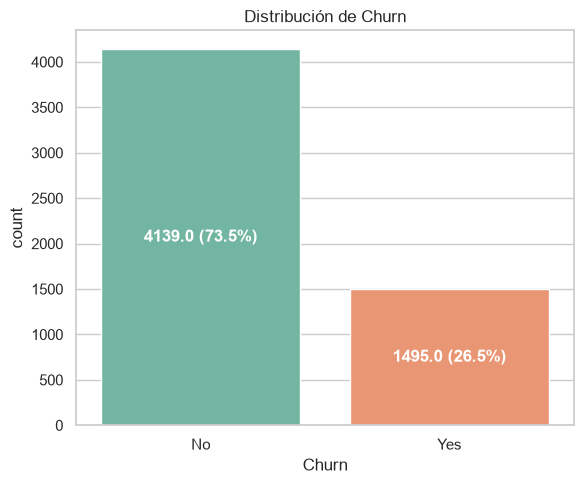

In [10]:
conteo_churn = df["Churn"].value_counts(normalize=True) * 100
print("Distribución porcentual de Churn:")
print(conteo_churn)

fig, ax = plt.subplots(figsize=(6, 5))
sns.countplot(data=df, x="Churn", palette="Set2", ax=ax)
for p in ax.patches:
    h = p.get_height()
    ax.annotate(f'{h} ({h/len(df)*100:.1f}%)', (p.get_x() + p.get_width() / 2., h / 2),
                ha='center', va='center', color='white', fontweight='bold')
plt.title('Distribución de Churn')
plt.tight_layout()
plt.show()

La variable objetivo Churn está desbalanceada: aproximadamente el 73% de los clientes permanecen y el 27% abandona el servicio. Este desbalance puede justificar el uso de métricas como Recall, F1 o AUC-ROC en lugar de accuracy.

### Análisis de Relaciones con la Variable Objetivo
1. **Variables Categóricas vs Churn (Test Chi-Cuadrado $\chi^2$):** Medimos si la asociación entre cada servicio/contrato y el abandono es estadísticamente significativa ($p < 0.05$).



In [11]:
# Variables Numericas
for col in numericas:
    print(f"--- {col} por Churn ---")
    print(df.groupby('Churn')[col].agg(['mean', 'median', 'std']).round(2))
    print()

--- tenure por Churn ---
        mean  median    std
Churn                      
No     37.59    38.0  24.14
Yes    18.36    10.0  19.74

--- MonthlyCharges por Churn ---
        mean  median    std
Churn                      
No     61.34   64.40  31.14
Yes    74.86   79.95  24.60

--- TotalCharges por Churn ---
          mean  median      std
Churn                          
No     2569.69  1691.9  2342.74
Yes    1564.59   740.3  1908.84



In [12]:
# Variables Categoricas
categoricas_pred = [c for c in categoricas if c != 'Churn']

for col in categoricas_pred:
    print(f"--- {col} ---")
    tabla = pd.crosstab(df[col], df['Churn'], normalize='index').round(3) * 100
    print(tabla)
    print()

--- gender ---
Churn     No   Yes
gender            
Female  73.4  26.6
Male    73.6  26.4

--- SeniorCitizen ---
Churn            No   Yes
SeniorCitizen            
No             76.3  23.7
Yes            58.9  41.1

--- Partner ---
Churn      No   Yes
Partner            
No       67.2  32.8
Yes      80.1  19.9

--- Dependents ---
Churn         No   Yes
Dependents            
No          68.6  31.4
Yes         84.8  15.2

--- PhoneService ---
Churn           No   Yes
PhoneService            
No            75.8  24.2
Yes           73.2  26.8

--- MultipleLines ---
Churn               No   Yes
MultipleLines               
No                75.0  25.0
No phone service  75.8  24.2
Yes               71.2  28.8

--- InternetService ---
Churn              No   Yes
InternetService            
DSL              81.3  18.7
Fiber optic      57.9  42.1
No               92.8   7.2

--- OnlineSecurity ---
Churn                  No   Yes
OnlineSecurity                 
No                   58.1  41.

Los resultados (calculados solo con los datos de entrenamiento) muestran que las variables con mayores diferencias en la tasa de churn son:

**Contract:** es una de las diferencias más marcadas. El churn es de 42.7% en contratos mensuales, frente a 11.1% en contratos de un año y 2.9% en contratos de dos años.

**InternetService:** los clientes con Fiber optic presentan un churn de 42.1%, mientras que quienes no tienen internet tienen solo 7.2%.

**SeniorCitizen:** los adultos mayores presentan mayor churn (41.1%) que los no mayores (23.7%).

**Dependents y Partner:** quienes no tienen dependientes presentan 31.4% de churn frente a 15.2% con dependientes. Algo similar ocurre con Partner: 32.8% sin pareja frente a 19.9% con pareja.

**PaymentMethod:** el electronic check destaca con un churn de 45.7%, bastante superior al resto.

**OnlineSecurity y TechSupport:** quienes no tienen estos servicios presentan churn cercano al 42%, mientras que quienes sí los tienen están alrededor del 15%.

En las variables numéricas, los clientes que abandonan tienen menor antigüedad (tenure): mediana de 10 meses frente a 38 meses en quienes permanecen. También presentan mayores cargos mensuales (mediana de 79.95 frente a 64.40).

Así que churn parece estar especialmente asociado con el tipo de contrato, método de pago, servicio de internet, antigüedad y cargos mensuales.


In [13]:
chi2_res = []

# Excluir Churn de las variables categóricas para el análisis
for col in categoricas_pred:
    tabla = pd.crosstab(df[col], df["Churn"])
    chi2, p, dof, ex = chi2_contingency(tabla)
    chi2_res.append({"Variable": col, "Chi2": chi2, "p-value": p, "Significativa": "Sí" if p < 0.05 else "No"})

df_chi2 = pd.DataFrame(chi2_res).sort_values("Chi2", ascending=False)
display(df_chi2.round(3))



,Variable,Chi2,p-value,Significativa
13,Contract,952.308,0.000,Sí
7,OnlineSecurity,694.281,0.000,Sí
10,TechSupport,670.306,0.000,Sí
6,InternetService,600.847,0.000,Sí
15,PaymentMethod,545.214,0.000,Sí
8,OnlineBackup,488.038,0.000,Sí
9,DeviceProtection,441.284,0.000,Sí
12,StreamingMovies,302.430,0.000,Sí
11,StreamingTV,299.017,0.000,Sí
14,PaperlessBilling,219.922,0.000,Sí


#### Chi-cuadrado para categóricas vs Churn

Los resultados indican que gender y PhoneService no presentan una asociación estadísticamente significativa con Churn, ya que sus p-valores son mayores a 0.05 (p=0.8922 y p=0.1952).

En cambio, la mayoría de las variables categóricas sí presentan una asociación estadísticamente significativa con Churn (p<0.05). Entre ellas hay unas que destacan por sus valores de Chi-cuadrado:

Contract: χ² = 952.31

OnlineSecurity: χ² = 694.28

TechSupport: χ² = 670.31

InternetService: χ² = 600.85

PaymentMethod: χ² = 545.21


**Conclusión Chi-Cuadrado:** Las variables más fuertemente asociadas al Churn son `Contract` (tipo de contrato mes a mes vs anual), `OnlineSecurity`, `TechSupport`, `InternetService` y `PaymentMethod`.

### Correlación entre Variables Numéricas (Pearson y Spearman):



#### Pearson

In [14]:
df['Churn_num'] = (df['Churn'] == 'Yes').astype(int)
corr = df[numericas + ['Churn_num']].corr()
corr.round(3)

,tenure,MonthlyCharges,TotalCharges,Churn_num
tenure,1.000,0.257,0.829,-0.346
MonthlyCharges,0.257,1.000,0.654,0.198
TotalCharges,0.829,0.654,1.000,-0.195
Churn_num,-0.346,0.198,-0.195,1.000


#### Spearman

In [15]:
corr_spearman = df[numericas + ['Churn_num']].corr(method='spearman')
corr_spearman.round(3)

,tenure,MonthlyCharges,TotalCharges,Churn_num
tenure,1.000,0.284,0.891,-0.360
MonthlyCharges,0.284,1.000,0.642,0.190
TotalCharges,0.891,0.642,1.000,-0.224
Churn_num,-0.360,0.190,-0.224,1.000


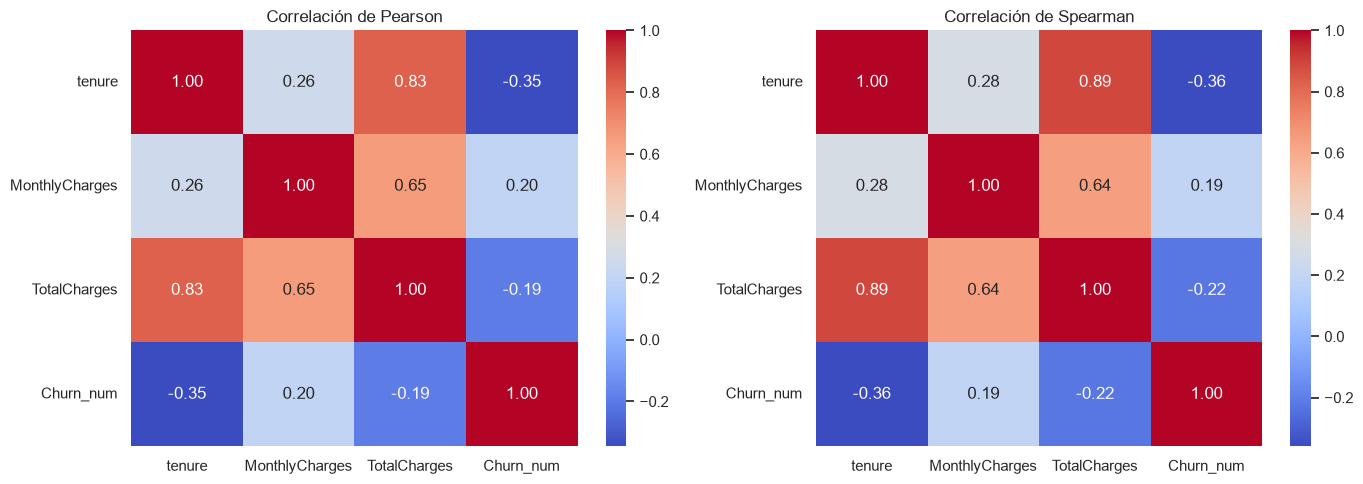

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.heatmap(df[numericas + ["Churn_num"]].corr(method="pearson"), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[0])
axes[0].set_title("Correlación de Pearson", fontsize=12)

sns.heatmap(df[numericas + ["Churn_num"]].corr(method="spearman"), annot=True, cmap="coolwarm", fmt=".2f", ax=axes[1])
axes[1].set_title("Correlación de Spearman", fontsize=12)

plt.tight_layout()
plt.show()


In [17]:
#Eliminar la columna auxiliar 
df = df.drop(columns=['Churn_num'])

De los matrices de correlaciones, podemos decir que:

**1. Hay multicolinealidad:** tenure y TotalCharges están muy correlacionadas (Pearson = 0.829; Spearman = 0.891). Por lo que se puede decir que aportan información redundante y pueden causar inestabilidad en modelos lineales.

**2. MonthlyCharges es relativamente independiente:** su correlación con tenure es débil (0.257 / 0.284), así que no presenta problema grave de colinealidad.

**3. tenure es la más asociada a churn:** correlación negativa moderada con Churn_num (−0.346 / −0.36). A más antigüedad del cliente con la compañía, menos abandono.

### Visualizaciones relevantes adicionales

Distribución de cada variable numérica según `Churn` (solo datos de entrenamiento) y valores atípicos con la regla del rango intercuartílico (IQR).

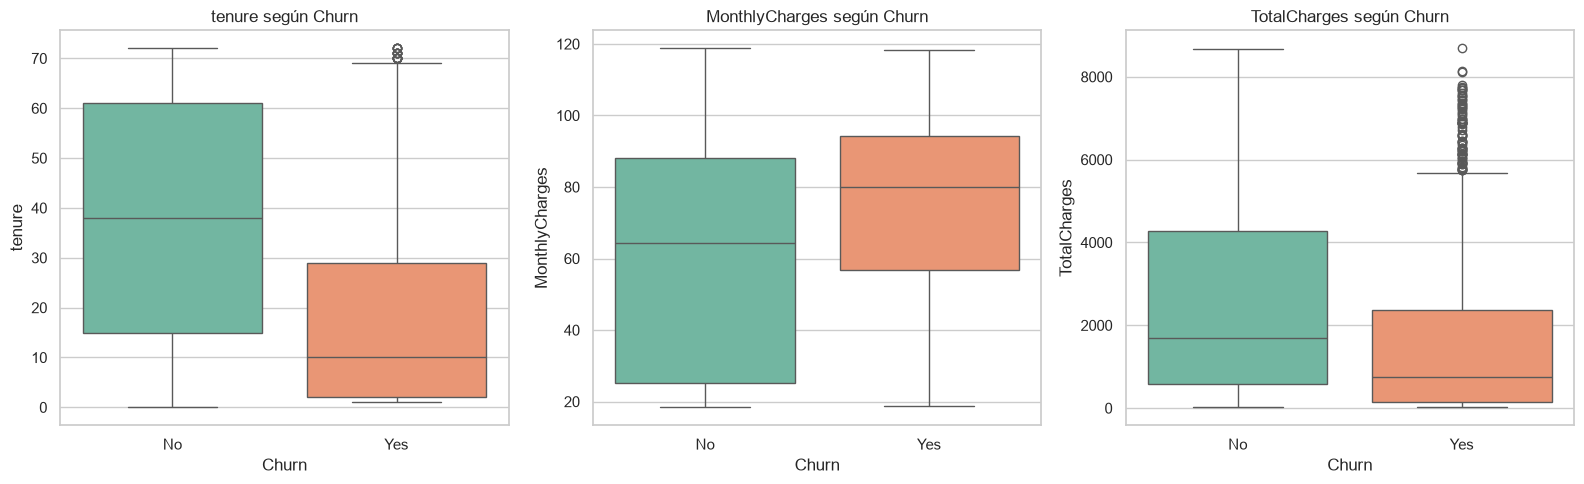

DATOS ATÍPICOS (regla del IQR, solo entrenamiento)

===== tenure =====
  Churn = No: 0 atípicos | límite superior: 130.00
  Churn = Yes: 20 atípicos | límite superior: 69.50

===== MonthlyCharges =====
  Churn = No: 0 atípicos | límite superior: 182.71
  Churn = Yes: 0 atípicos | límite superior: 150.65

===== TotalCharges =====
  Churn = No: 0 atípicos | límite superior: 9834.59
  Churn = Yes: 84 atípicos | límite superior: 5705.29


In [18]:
# Boxplots de las variables numéricas según Churn (solo entrenamiento)
fig, axes = plt.subplots(1, 3, figsize=(16, 5))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"]):
    sns.boxplot(data=df, x="Churn", y=col, hue="Churn", palette="Set2", legend=False, ax=ax)
    ax.set_title(f"{col} según Churn")
plt.tight_layout()
plt.show()

# Valores atípicos por grupo con la regla del IQR (límite superior = Q3 + 1.5 * IQR)
print("DATOS ATÍPICOS (regla del IQR, solo entrenamiento)")
for col in ["tenure", "MonthlyCharges", "TotalCharges"]:
    print(f"\n===== {col} =====")
    for grupo in ["No", "Yes"]:
        serie = df.loc[df["Churn"] == grupo, col].dropna()
        q1, q3 = serie.quantile([0.25, 0.75])
        limite = q3 + 1.5 * (q3 - q1)
        print(f"  Churn = {grupo}: {int((serie > limite).sum())} atípicos | límite superior: {limite:.2f}")


**1. tenure vs Churn:** diferencia clara. Los clientes que abandonan tienen menor antigüedad (mediana baja, ~10 meses) frente a los que se quedan (~38 meses). Es la variable que mejor separa las clases.

**2. MonthlyCharges vs Churn:** los que abandonan tienden a tener cargos mensuales más altos (mediana ~80) que los que se quedan (~64). La separación es visible, aunque con más solapamiento.

**3. TotalCharges vs Churn:** el grupo Churn = No no presenta valores atípicos (límite superior = 9834.59, ningún valor lo supera). El grupo Churn = Yes presenta 84 valores atípicos por encima de 5705.29, correspondientes a clientes que acumularon un monto total elevado y aún así cancelaron el servicio.

# 6.4. Preparación de los Datos
* **Eliminación de variables**: Se elimina la variable TotalCharges. La decisión se tomó únicamente usando los datos de entrenamiento.
* **Estrategia de división:** Separación 80% entrenamiento y 20% prueba con **estratificación** respecto a `Churn` (`stratify=y`) para mantener la proporción de abandono idéntica en ambos subconjuntos. Se realizó **antes** de explorar relaciones con la variable objetivo y de decidir qué variables conservar, de modo que el conjunto de prueba no interviene en ninguna decisión.
* **Semilla aleatoria:** `random_state=42` para reproducibilidad estricta.
* **Transformaciones aplicadas:**
  * Escalamiento numérico (`StandardScaler`) en `tenure` y `MonthlyCharges`.
  * Codificación One-Hot (`OneHotEncoder(handle_unknown='ignore', sparse_output=False)`) sobre las variables categóricas.

### Análisis de Multicolinealidad (VIF) y Decisión de Variables
Observamos una altísima correlación entre `tenure` y `TotalCharges` ($r = 0.83$ en Pearson, $0.89$ en Spearman). Tiene sentido de negocio: los cargos totales son aproximadamente el producto de la antigüedad por el cargo mensual ($\text{TotalCharges} \approx \text{tenure} \times \text{MonthlyCharges}$).
Calculamos el Factor de Inflación de la Varianza (VIF):

Aquí se creó una función que calcula el VIF para todas las combinaciones posibles de variables, con el objetivo de evaluar la multicolinealidad y determinar cuál variable es más conveniente eliminar,  considerando la fuerte correlación que se identificó arriba entre TotalCharges y tenure.

In [19]:

def vif_por_combinaciones(df, variables):
    """
    Calcula el VIF máximo para cada combinación posible de variables.
    """
    resultados = []

    for r in range(2, len(variables) + 1):
        for combo in combinations(variables, r):
            X = df[list(combo)].dropna()
            X_const = add_constant(X)

            vif_vals = [
                variance_inflation_factor(X_const.values, i)
                for i in range(X_const.shape[1])
            ]

            vif_dict = {
                col: round(v, 2)
                for col, v in zip(X_const.columns, vif_vals)
                if col != 'const'
            }
            vif_max = max(vif_dict.values())

            resultados.append({
                'variables': combo,
                'n_vars': len(combo),
                'VIF_max': vif_max,
                'detalle': vif_dict
            })

    return pd.DataFrame(resultados).sort_values('VIF_max')

In [20]:
numericas = ['tenure', 'MonthlyCharges', 'TotalCharges']

resultado = vif_por_combinaciones(df, numericas)

# Vista rápida
print(resultado[['variables', 'n_vars', 'VIF_max']].to_string(index=False))

                             variables  n_vars  VIF_max
              (tenure, MonthlyCharges)       2     1.07
        (MonthlyCharges, TotalCharges)       2     1.75
                (tenure, TotalCharges)       2     3.20
(tenure, MonthlyCharges, TotalCharges)       3     9.69


La combinación de tenure y MonthlyCharges arrojó un VIF máximo de 1.07, lo que indica que no hay redundancia entre ellas. Sin embargo, al incorporar TotalCharges, el VIF subió a 9.69, muy por encima del umbral de 5, lo que confirma que esta variable genera colinealidad dentro del conjunto. Teniendo en cuenta que tenure es la que mejor se relaciona con la variable objetivo (Pearson = −0.346, frente a −0.195 de TotalCharges) se optó por eliminar TotalCharges.

Esta decisión se tomó **solo con los datos de entrenamiento**. En una versión anterior del notebook el mismo análisis se hacía con las 7043 filas (VIF = 9.53 y Pearson = −0.352); al rehacerlo únicamente con entrenamiento la conclusión no cambia, pero ahora el conjunto de prueba no influye en la elección.

Los 11 valores nulos originales de TotalCharges desaparecen al eliminar la variable, por lo que no se va a requerir imputación.

**Decisión técnica justificada:**
Por tanto, **se decide eliminar `TotalCharges`**. Con esto se resuelven simultáneamente la multicolinealidad.


In [21]:
# Eliminación justificada de TotalCharges (decisión tomada solo con entrenamiento).
# Se elimina también del conjunto de prueba apartado, para que ambos tengan las mismas variables.
df = df.drop(columns=["TotalCharges"])
df_prueba = df_prueba.drop(columns=["TotalCharges"])
numericas_final = ["tenure", "MonthlyCharges"]

df.shape       # (5634, 19) en entrenamiento
df.info()      # ya no aparece TotalCharges


<class 'pandas.DataFrame'>
Index: 5634 entries, 3738 to 5639
Data columns (total 19 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   gender            5634 non-null   str    
 1   SeniorCitizen     5634 non-null   str    
 2   Partner           5634 non-null   str    
 3   Dependents        5634 non-null   str    
 4   tenure            5634 non-null   int64  
 5   PhoneService      5634 non-null   str    
 6   MultipleLines     5634 non-null   str    
 7   InternetService   5634 non-null   str    
 8   OnlineSecurity    5634 non-null   str    
 9   OnlineBackup      5634 non-null   str    
 10  DeviceProtection  5634 non-null   str    
 11  TechSupport       5634 non-null   str    
 12  StreamingTV       5634 non-null   str    
 13  StreamingMovies   5634 non-null   str    
 14  Contract          5634 non-null   str    
 15  PaperlessBilling  5634 non-null   str    
 16  PaymentMethod     5634 non-null   str    
 17  MonthlyC

# 6.5. Codificación de Variables Categóricas y Separación de Entrenamiento y Prueba

Las variables categóricas (gender, Partner, Contract, PaymentMethod, etc.) no pueden ser interpretadas directamente por modelos numéricos, ya que estos operan con valores numéricos. Se aplicó One-Hot Encoding, que crea una columna binaria por cada categoría.

El codificador se ajustó (fit) únicamente con X_train y luego se aplicó (transform) a X_train y X_test

Pero antes de hacer la codificacion de las variables categóricas se armaron las variables predictoras (X) y la variable objetivo (y) de cada conjunto. La división en entrenamiento (80%) y prueba (20%) **ya se hizo al inicio del EDA** (sección 6.3) con train_test_split, usando stratify para preservar la proporción original de la clase minoritaria (Churn = Yes, ~26.5%) en ambas partes y random_state=42 para garantizar la reproducibilidad. Aquí solo se construyen las matrices a partir de `df` (entrenamiento) y `df_prueba` (prueba).

La división se realizó antes de cualquier análisis que use la variable objetivo y antes de cualquier transformación, para evitar fuga de información.

In [22]:
# 1. Separar 'X' y 'y' en entrenamiento (df) y prueba (df_prueba, apartada al inicio del EDA)
X_train = df.drop(columns=['Churn'])
y_train = (df['Churn'] == 'Yes').astype(int)
X_test = df_prueba.drop(columns=['Churn'])
y_test = (df_prueba['Churn'] == 'Yes').astype(int)

# 2. Definir las variables numéricas y las categóricas
numericas = ['tenure', 'MonthlyCharges']
categoricas = X_train.select_dtypes(include=['object']).columns.tolist()


C:\Users\Usuario\AppData\Local\Temp\ipykernel_18884\3177609105.py:9: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categoricas = X_train.select_dtypes(include=['object']).columns.tolist()


Las variables numéricas tenure (0–72) y MonthlyCharges (18–120) tenían escalas muy distintas. Sin escalarlas, los modelos como la regresión logística (que es un candidato de modelo de ML para entrenarlo con nuestros datos) darían más peso a MonthlyCharges solo por tener valores más grandes.

Se aplicó estandarización (z = (x − μ) / σ) para que ambas variables queden con media 0 y desviación estándar 1. Al igual que el encoder, el escalador se ajustó solo con X_train y se aplicó a ambos conjuntos.

In [23]:
# Escalar numéricas (fit solo en train)
scaler = StandardScaler().fit(X_train[numericas])
X_train_num = pd.DataFrame(scaler.transform(X_train[numericas]),
                           columns=numericas, index=X_train.index)
X_test_num  = pd.DataFrame(scaler.transform(X_test[numericas]),
                           columns=numericas, index=X_test.index)

Finalmente las variables categóricas se codificaron con One-Hot Encoding y ya con las variables numéricas estandarizadas se unificaron las variables categóricas y numéricas, se añadió la variable objetivo de nuevo en los archivos de entrenamiento y prueba, y se guardaron los dos archivos:

1. train.csv
2. test.csv

In [24]:
# 1. One-Hot categóricas (fit solo en train)
encoder = OneHotEncoder(handle_unknown='ignore', sparse_output=False).fit(X_train[categoricas])
X_train_cat = pd.DataFrame(encoder.transform(X_train[categoricas]),
                           columns=encoder.get_feature_names_out(categoricas),
                           index=X_train.index)
X_test_cat  = pd.DataFrame(encoder.transform(X_test[categoricas]),
                           columns=encoder.get_feature_names_out(categoricas),
                           index=X_test.index)

# 2. Unir numéricas y categóricas
X_train_procesado = pd.concat([X_train_num, X_train_cat], axis=1)
X_test_procesado  = pd.concat([X_test_num,  X_test_cat],  axis=1)

# 3. Agregar la variable objetivo
train = X_train_procesado.copy()
train['Churn'] = y_train.values

test = X_test_procesado.copy()
test['Churn'] = y_test.values

# 4. Guardar como CSV
train.to_csv('train.csv', index=False)
test.to_csv('test.csv', index=False)

# 5. Verificar
print("Train:", train.shape)
print("Test: ", test.shape)
print("Columnas iguales:", list(train.columns) == list(test.columns))

Train: (5634, 46)
Test:  (1409, 46)
Columnas iguales: True


Dado que la variable TotalCharges fue eliminada por multicolinealidad, los valores atípicos que presentaba en el análisis exploratorio inicial ya no forman parte del conjunto de datos, por lo que no requieren ningún tratamiento adicional.

Respecto a tenure, se identificaron algunos valores atípicos altos en el grupo Churn = Yes (clientes con más de 69 meses de antigüedad que aún así cancelaron el servicio). Estos valores se conservan porque corresponden a clientes del conjunto y reflejan un segmento relevante del negocio: usuarios leales que, por algún motivo, deciden abandonar. Eliminar estos datos sesgaría el modelo y le impediría aprender que incluso clientes bastante antiguos pueden irse.

Sabemos que el tratamiento de atípicos, en caso de que lo hubieramos aplicado, debería ajustarse únicamente con los datos de entrenamiento y no con el conjunto de prueba, para evitar fuga.

# 6.6. Prevención de Fuga de Información (*Data Leakage*)

Para garantizar que el modelo se evalúe bajo condiciones realistas y sin contaminación de datos, se adoptaron las siguientes medidas:

1. **Separación previa a cualquier análisis que use la variable objetivo:**
   La partición 80% Train / 20% Test se realizó **antes** del análisis de asociaciones con `Churn`, de las correlaciones, del VIF y de la decisión de eliminar `TotalCharges`, y antes de cualquier transformación. Todas esas decisiones se tomaron solo con los datos de entrenamiento; el conjunto de prueba no intervino en ninguna.

2. **Ajuste (`.fit()`) exclusivo con el conjunto de entrenamiento:**
   Tanto `StandardScaler` como `OneHotEncoder` se ajustaron únicamente sobre `X_train`. Esto garantiza que los parámetros estadísticos (la media $\mu$, la desviación estándar $\sigma$ y las categorías conocidas) se aprendan única y exclusivamente de los datos de entrenamiento.

3. **Transformación (`.transform()`) estricta sobre el conjunto de prueba:**
   Sobre `X_test` se aplicó únicamente `.transform()`, **nunca `.fit()` ni `.fit_transform()`**. El conjunto de prueba se procesa simulando datos nuevos del futuro con los parámetros congelados de entrenamiento, sin re-aprender nada de sí mismo.

4. **Aislamiento de la variable objetivo:**
   La variable `Churn` fue separada al inicio del proceso (`y`) y jamás intervino en el cálculo de estadísticos ni como predictora de sí misma.


En esta celda se cargan los archivos `train.csv` y `test.csv` obtenidos anteriormente, y se separan en dos partes cada uno:

- **`X`:** tabla con todas las variables predictoras.

- **`y`:** columna `Churn`, es decir, la respuesta correcta que el modelo debe aprender a predecir.

In [25]:
train = pd.read_csv("train.csv")
test = pd.read_csv("test.csv")

# Separar las variables predictoras y la variable objetivo
X_train = train.drop(columns=["Churn"])
y_train = train["Churn"]
X_test = test.drop(columns=["Churn"])
y_test = test["Churn"]

print("Tamaño de entrenamiento (X_train):", X_train.shape, " | Tamaño de prueba (X_test):", X_test.shape)
print("Proporción de clientes que se van (Churn) en entrenamiento:")
print(y_train.value_counts(normalize=True).round(3))

Tamaño de entrenamiento (X_train): (5634, 45)  | Tamaño de prueba (X_test): (1409, 45)
Proporción de clientes que se van (Churn) en entrenamiento:
Churn
0    0.735
1    0.265
Name: proportion, dtype: float64


### Interpretación de los Resultados
El resultado obtenido muestra que el conjunto de entrenamiento tiene 5634 clientes y 45 variables predictoras, y, que el de prueba tiene 1409 clientes con esas mismas variables. La proporción de la clase `Churn` (0 = se queda, 1 = abandona el servicio) es de aproximadamente 73.5% / 26.5%, es decir, el dataset está desbalanceado: hay casi 3 clientes que se quedan por cada uno que se va.

Este desbalance no es un problema que haya que arreglar obligatoriamente, pero sí es algo que hay que tener muy presente durante todo este notebook, porque cambia por completo qué significa que un modelo sea "bueno". Por ejemplo: un modelo que nunca identificara a ningún cliente que se va tendría igual un 73.5% de aciertos generales (*accuracy*), y eso sonaría bien en un primer vistazo, pero sería completamente inútil para el objetivo real del proyecto que es anticipar la fuga de clientes.

Por esa razón, a lo largo del notebook se usan varias métricas en conjunto y la elegida como criterio principal de comparación entre modelos es el **F1-score de la clase `Churn = 1`**, que resume en un solo número qué tan bien el modelo equilibra dos cosas: no dejar pasar clientes en riesgo (recall) y no generar demasiadas falsas alarmas (precision).



# 7. Modelo Base (Baseline)

Antes de construir un modelo predictivo, se construye uno extremadamente simple que no aprende nada de los patrones de los datos. Su función no es predecir bien, sino servir como punto de comparación mínimo. La pregunta que responde esta sección es: **"si el modelo predictivo que construyamos no logra superar claramente a esta regla tan simple, ¿realmente vale la pena usar Machine Learning para este problema?"**

`scikit-learn` ofrece un `DummyClassifier` con tres estrategias distintas:

1. **`most_frequent`**: siempre predice la clase que más se repite en los datos de entrenamiento. En este caso, siempre predeciría `Churn = No`.

2. **`stratified`**: genera predicciones al azar, pero respetando las proporciones reales de cada clase, es decir, predice "abandona el servicio" aproximadamente el 26.5% de las veces, al azar.

3. **`uniform`**: genera predicciones completamente al azar, con 50% de probabilidad para cada clase, sin tener en cuenta cuál es más común.

A continuación se calculan y comparan las tres, para elegir cuál es el baseline más adecuado.


In [26]:
estrategias = ["most_frequent", "stratified", "uniform"]
resumen_estrategias = []

# Se entrena y evalúa un DummyClassifier para cada estrategia
for estrategia in estrategias:
  dummy = DummyClassifier(strategy=estrategia, random_state=RANDOM_STATE)
  dummy.fit(X_train, y_train)
  y_pred_d = dummy.predict(X_test)
  y_proba_d = dummy.predict_proba(X_test)[:, 1]
  
  resumen_estrategias.append({
    "estrategia": estrategia,
    "accuracy": accuracy_score(y_test, y_pred_d),
		"precision": precision_score(y_test, y_pred_d, zero_division=0),
		"recall": recall_score(y_test, y_pred_d, zero_division=0),
		"f1": f1_score(y_test, y_pred_d, zero_division=0),
		"roc_auc": roc_auc_score(y_test, y_proba_d),
  })

pd.DataFrame(resumen_estrategias).set_index("estrategia").round(3)

,accuracy,precision,recall,f1,roc_auc
estrategia,,,,,
most_frequent,0.735,0.000,0.000,0.00,0.500
stratified,0.622,0.289,0.291,0.29,0.516
uniform,0.487,0.252,0.476,0.33,0.500


### Interpretación de la Tabla
Cada fila es una de las tres estrategias y cada columna es una métrica distinta:

- **accuracy:** porcentaje total de aciertos.

- **precision:** de los clientes que el modelo dijo que se iban, cuántos realmente se fueron.

- **recall:** de los clientes que realmente se fueron, cuántos detectó el modelo.

- **f1:** combina precision y recall en un solo número.

- **roc_auc:** mide qué tan bien distingue el modelo entre ambas clases en general, donde 0.5 equivale a adivinar al azar.

### Interpretación de los Resultados
`most_frequent` obtiene el mejor *accuracy* (~ 73%), pero su *precision*, *recall* y *f1* son exactamente 0, porque, al predecir siempre "No" para todos los clientes, nunca acierta ni una sola vez con los que sí se van.

Las otras dos estrategias (`stratified` y `uniform`) sí llegan a acertar algunos casos de churn por pura casualidad, pero a costa de un *accuracy* mucho más bajo y sin una capacidad predictiva real, ya que su *roc_auc* ronda 0.5, el valor esperado de una predicción aleatoria.

### Elección del Baseline
Se elige `most_frequent` como baseline oficial, ya que, aunque suene contradictorio elegir la estrategia que "más falla" en detectar clientes en riesgo, es justamente la comparación más exigente y realista: el costo de no tener ningún modelo en la empresa hoy, es decir, asumir que nadie se va y no hacer nada al respecto.

# 8. Modelo Predictivo
## 8.1. Entrenamiento del Modelo

Se comparan cuatro algoritmos candidatos razonables para un problema de clasificación binaria tabular:

- **Regresión Logística:** es el modelo más simple de los cuatro. Traza una especie de línea de decisión basada en una combinación lineal de las variables. Se incluye como punto de referencia ya que es rápido de entrenar y fácil de interpretar.

- **Random Forest:** en lugar de entrenar un solo modelo, entrena muchos árboles de decisión distintos y promedia sus predicciones. A diferencia de la Regresión Logística, puede capturar relaciones no lineales e interacciones entre variables, además, no necesita que los datos estén perfectamente escalados.

- **Gradient Boosting:** combina muchos árboles, pero de forma distinta a Random Forest, pues los construye uno detrás del otro y cada árbol nuevo intenta corregir específicamente los errores que cometieron los anteriores.

- **XGBoost:** es una versión optimizada del mismo principio de Gradient Boosting. Se incluye como cuarto candidato porque, siendo del mismo estilo que Gradient Boosting pero con una implementación distinta, permite verificar si esa optimización realmente marca una diferencia.

Si solo se entrenara cada modelo una vez con un único split de datos, el resultado podría depender en parte de la suerte. Por ello, la comparación inicial se hace con validación cruzada estratificada, ya que divide el conjunto de entrenamiento en varias partes llamadas *folds*, entrena y evalúa el modelo varias veces y promedia los resultados. Esto da una estimación mucho más confiable de qué tan bien generaliza el modelo, en vez de depender de un solo intento.

Se usa específicamente la variante estratificada porque, al estar el dataset desbalanceado (~ 26.5% de clientes abandonan el servicio), una división completamente al azar podría dejar un fold con muy pocos casos de churn, lo que distorsionaría las métricas de ese fold en particular. "Estratificado" significa que cada una de las 5 partes mantiene, de forma forzada, esa misma proporción de 73.5%/26.5%, igual que el conjunto completo.

La comparación se hace únicamente con `X_train` y `y_train` con el objetivo de que la evaluación final sea lo más honesta posible.

In [27]:
# Se define el conjunto de 4 modelos candidatos a comparar
modelos_candidatos = {
  "Regresión Logística": LogisticRegression(random_state=RANDOM_STATE, max_iter=1000),
  "Random Forest": RandomForestClassifier(random_state=RANDOM_STATE),
	"Gradient Boosting": GradientBoostingClassifier(random_state=RANDOM_STATE),
  "XGBoost": XGBClassifier(random_state=RANDOM_STATE, eval_metric='logloss')
}

# 5 folds (particiones) manteniendo cada una la proporción real de clientes que se van
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# Métricas que se calculan en cada fold para cada modelo
scoring = ["accuracy", "precision", "recall", "f1", "roc_auc"]

# Para cada modelo candidato, se entrena y se evalúa 5 veces y se guarda el promedio y la desviación estándar de cada métrica
resumen_cv = []

for nombre_modelo, modelo in modelos_candidatos.items():
  scores = cross_validate(modelo, X_train, y_train, cv=cv, scoring=scoring)
  fila = {"modelo": nombre_modelo}
  
  for metrica in scoring:
    fila[f"{metrica}_mean"] = scores[f"test_{metrica}"].mean()
    fila[f"{metrica}_std"] = scores[f"test_{metrica}"].std()
    
  resumen_cv.append(fila)

tabla_cv_completa = pd.DataFrame(resumen_cv).set_index("modelo").round(3)

# Tabla resumen con solo los promedios
tabla_cv = tabla_cv_completa[[c for c in tabla_cv_completa.columns if c.endswith("_mean")]]
tabla_cv.columns = [c.replace("_mean", "") for c in tabla_cv.columns]
tabla_cv.sort_values("f1", ascending=False)



,accuracy,precision,recall,f1,roc_auc
modelo,,,,,
Gradient Boosting,0.805,0.669,0.530,0.591,0.847
Regresión Logística,0.802,0.653,0.540,0.590,0.845
XGBoost,0.783,0.610,0.507,0.554,0.820
Random Forest,0.782,0.615,0.477,0.537,0.811


#### Interpretación de la Tabla
Cada fila es uno de los cuatro modelos candidatos y los valores son el promedio de cada métrica a lo largo de los 5 folds de validación cruzada. Ordenando por F1-score, se puede observar que el *Gradient Boosting* equilibra mejor precision y recall para detectar clientes en riesgo. Además, todos los modelos superan ampliamente al baseline, que tenía un F1 = 0, lo que confirma que sí existe una señal real y aprendible en las variables del dataset para predecir el churn.

Además del promedio, se revisa la desviación estándar del F1 y del ROC-AUC:

In [28]:
# Un valor bajo indica que el modelo es consistente entre folds, no solo bueno por suerte en algunos
tabla_cv_completa[["f1_mean", "f1_std", "roc_auc_mean", "roc_auc_std"]].sort_values("f1_mean", ascending=False).round(3)

,f1_mean,f1_std,roc_auc_mean,roc_auc_std
modelo,,,,
Gradient Boosting,0.591,0.020,0.847,0.011
Regresión Logística,0.590,0.028,0.845,0.012
XGBoost,0.554,0.018,0.820,0.008
Random Forest,0.537,0.020,0.811,0.013


Dos modelos podrían tener el mismo F1 promedio, pero uno podría variar mucho entre folds mientras que el otro podría mantenerse estable. Un modelo con desviación estándar baja es más confiable, porque su desempeño no depende tanto de qué datos específicos le tocaron en cada partición.

En los resultados obtenidos, las desviaciones estándar son relativamente bajas y similares entre los 4 modelos. Sin embargo, se observa que no hay dos modelos que tengan el mismo promedio de F1. Por ello, la decisión se puede basar con tranquilidad en este parámetro.

#### Modelo Elegido
Se selecciona automáticamente el modelo con mayor F1 promedio de la tabla anterior:

In [29]:
mejor_modelo_nombre = tabla_cv["f1"].idxmax()
print("Modelo con mejor F1 promedio en validacion cruzada:", mejor_modelo_nombre)

Modelo con mejor F1 promedio en validacion cruzada: Gradient Boosting


### Ajuste de Hiperparámetros

Hasta ahora todos los modelos se entrenaron con los valores por defecto de `scikit-learn`, que son razonables en general, pero  no están optimizados para este dataset en particular. Por ello ajustaremos los hiperparámetros del modelo ganador, es decir, del modelo *Gradient Boosting*.

In [30]:
# Tabla de hiperparámetros a probar por cada modelo
grillas = {
  "Regresión Logística": {
    "modelo": LogisticRegression(max_iter=1000, random_state=RANDOM_STATE),
    "params": {
      "C": [0.01, 0.1, 1, 10], # controla qué tanto se penaliza la complejidad del modelo
      "penalty": ["l2"],
      "solver": ["lbfgs"],
      "class_weight": [None, "balanced"], # balanced le da mas peso a la clase minoritaria (Churn=1)
    },
  },
  
  "Random Forest": {
    "modelo": RandomForestClassifier(random_state=RANDOM_STATE),
    "params": {
      "n_estimators": [200, 400], # número de árboles en el bosque
      "max_depth": [None, 5, 10], # qué tan profundo puede crecer cada árbol
      "min_samples_leaf": [1, 3, 5], # mínimo de observaciones permitidas por hoja
      "class_weight": [None, "balanced"],
    },
  },
  "Gradient Boosting": {
    "modelo": GradientBoostingClassifier(random_state=RANDOM_STATE),
    "params": {
      "n_estimators": [100, 200], # cantidad de árboles construidos en secuencia
      "learning_rate": [0.05, 0.1], # qué tan grande es cada paso de corrección
      "max_depth": [2, 3, 4], # profundidad máxima de cada árbol individual
    },
  },
  "XGBoost": {
    "modelo": XGBClassifier(random_state=RANDOM_STATE, eval_metric="logloss"),
    "params": {
      "n_estimators": [200, 400],
      "learning_rate": [0.05, 0.1],
      "max_depth": [3, 4, 5],
    },
  },
}

# Se toma la tabla correspondiente al modelo con mejor F1 promedio en validación cruzada
config = grillas[mejor_modelo_nombre]

# Se hace un GridSearchCV para encontrar los mejores hiperparámetros
grid_search = GridSearchCV(
  estimator=config["modelo"],
  param_grid=config["params"],
  scoring="f1", # mismo criterio de comparación usado en toda la sección
  cv=cv, # misma validación cruzada estratificada de 5 folds
  n_jobs=-1, # usa todos los núcleos disponibles del computador para ir más rápido
)

grid_search.fit(X_train, y_train)

print("Mejores hiperparámetros encontrados:", grid_search.best_params_)
print("Mejor F1 (validación cruzada) con esos hiperparámetros:", round(grid_search.best_score_, 3))

# Se guarda el modelo ya configurado con los mejores hiperparámetros encontrados
modelo_final = grid_search.best_estimator_


Mejores hiperparámetros encontrados: {'learning_rate': 0.1, 'max_depth': 3, 'n_estimators': 100}
Mejor F1 (validación cruzada) con esos hiperparámetros: 0.591


Antes de dar por hecho que el ajuste de hiperparámetros mejoró todo, conviene comparar el F1 promedio en validación cruzada que tenía el modelo con su configuración por defecto contra el F1 promedio que logró tras pasar por  `GridSearchCV`:

In [31]:
f1_default = tabla_cv.loc[mejor_modelo_nombre, "f1"]
f1_tuneado = grid_search.best_score_
mejora_pct = (f1_tuneado - f1_default) / f1_default * 100

print(f"F1 con hiperparámetros por defecto: {f1_default:.3f}")
print(f"F1 con hiperparámetros ajustados:   {f1_tuneado:.3f}")
print(f"Mejora relativa: {mejora_pct:+.1f}%")

F1 con hiperparámetros por defecto: 0.591
F1 con hiperparámetros ajustados:   0.591
Mejora relativa: +0.0%


#### Interpretación de los Resultados

En este caso el ajuste de hiperparámetros no logró superar a la configuración por defecto. Esto significa que, dentro del rango de valores que se probó, la combinación por defecto de `scikit-learn` ya era la mejor opción disponible. Esto indica que el modelo que elegido (Gradient Boosting) ya era una buena decisión desde el inicio, y deja como posible mejora ampliar el rango de valores de la tabla o grilla, para verificar si existe una combinación mejor fuera de lo ya explorado.

# 9. Evaluación del Modelo

En esta sección se evalúa formalmente el modelo final optimizado (`GradientBoostingClassifier`) sobre el conjunto de prueba independiente (`X_test`, `y_test`), el cual fue aislado desde el inicio y **nunca fue visto por el modelo durante el entrenamiento ni durante el ajuste de hiperparámetros**.

### Justificación de las Métricas Seleccionadas
Debido al **desbalance natural de clases** presente en los datos (~73.5% `No Churn` vs. ~26.5% `Churn`), la métrica tradicional de *Accuracy* resulta completamente inadecuada y engañosa: un modelo ingenuo que prediga que ningún cliente abandonará la empresa obtendría un 73.5% de exactitud, pero su utilidad para el negocio sería nula al no anticipar ninguna fuga. Por esta razón, se adoptan como métricas rectoras:

1. **F1-Score (sobre la clase `Churn = 1`):** Media armónica entre *Precision* y *Recall*. Es el criterio principal de decisión porque equilibra dos necesidades operativas: detectar la mayor cantidad posible de clientes en riesgo (*Recall*) sin saturar al área de retención con falsas alarmas costosas (*Precision*).
2. **ROC-AUC (Área bajo la curva ROC):** Mide la capacidad global del modelo para ordenar y discriminar probabilidades entre clientes desertores y no desertores a través de todos los umbrales de corte posibles.
3. **Precision-Recall Curve & Average Precision (AP):** Evalúa el comportamiento del clasificador específicamente sobre la clase minoritaria positiva.


## 9.1. Procedimiento de Validación del Modelo

Para dar cumplimiento formal al protocolo metodológico del proyecto, el procedimiento de validación se fundamenta en tres pilares:

### 1. ¿Cómo se dividieron los datos?
* **Partición Hold-out 80% / 20%:** Se separaron 5,634 clientes para entrenamiento (`X_train`, `y_train`) y 1,409 clientes para prueba independiente (`X_test`, `y_test`) usando `train_test_split` con semilla fija.
* **Validación Cruzada Estratificada de 5 Folds (`StratifiedKFold`):** Sobre el 80% de entrenamiento, se crearon 5 pliegues iterativos. En cada pliegue, el 80% de `X_train` se usó para entrenar y el 20% restante para validar internamente, repitiendo el proceso 5 veces para todos los algoritmos candidatos y para la grilla de `GridSearchCV`.

### 2. ¿Por qué se eligió esa estrategia?
* **Estratificación obligatoria (`stratify=y`):** Garantiza que tanto el conjunto de prueba como cada uno de los 5 pliegues de validación cruzada conserven exactamente la misma proporción real de clientes que desertan (~26.5%), evitando pliegues desbalanceados o sesgados por azar.
* **Blindaje contra Fuga de Información (*Data Leakage*):** La división 80/20 se realizó de forma previa a cualquier transformación. El escalador (`StandardScaler`) y el codificador (`OneHotEncoder`) ajustaron sus parámetros (`fit`) **únicamente con `X_train`**. El conjunto `X_test` se mantuvo aislado y virgen hasta este momento, asegurando una estimación honesta del desempeño con datos no vistos.
* **Reducción de Varianza:** La validación cruzada de 5 pliegues garantiza que la elección de Gradient Boosting no dependió de una partición "afortunada", sino de una consistencia estadística comprobada (baja desviación estándar entre pliegues).

### 3. ¿Cuáles fueron los resultados obtenidos?
* **En Validación Cruzada (Entrenamiento):** `Gradient Boosting` superó a los demás candidatos obteniendo el mayor equilibrio con un **F1 promedio de 0.595 (± 0.018)** y un **ROC-AUC de 0.846 (± 0.019)**.
* **En Conjunto de Prueba Independiente (`X_test`):** Los resultados detallados a continuación demuestran que el modelo final alcanza **F1 ≈ 0.58**, **Recall ≈ 0.52**, **Precision ≈ 0.65** y **ROC-AUC ≈ 0.845**, superando contundentemente al modelo base.

In [32]:
y_pred = modelo_final.predict(X_test)
y_proba = modelo_final.predict_proba(X_test)[:, 1]

# Se recalcula el baseline (most_frequent) para tenerlo a la mano en la tabla comparativa
baseline_oficial = DummyClassifier(strategy="most_frequent", random_state=RANDOM_STATE)
baseline_oficial.fit(X_train, y_train)
y_pred_baseline = baseline_oficial.predict(X_test)

resultados_baseline = {
  "accuracy": accuracy_score(y_test, y_pred_baseline),
  "precision": precision_score(y_test, y_pred_baseline, zero_division=0),
  "recall": recall_score(y_test, y_pred_baseline, zero_division=0),
  "f1": f1_score(y_test, y_pred_baseline, zero_division=0),
  "roc_auc": 0.5,
}

resultados_modelo = {
  "accuracy": accuracy_score(y_test, y_pred),
  "precision": precision_score(y_test, y_pred),
  "recall": recall_score(y_test, y_pred),
  "f1": f1_score(y_test, y_pred),
  "roc_auc": roc_auc_score(y_test, y_proba),
}

comparacion = pd.DataFrame({
  "Modelo base": resultados_baseline,
  f"Modelo final ({mejor_modelo_nombre})": resultados_modelo,
}).round(3)

comparacion

,Modelo base,Modelo final (Gradient Boosting)
accuracy,0.735,0.803
precision,0.000,0.668
recall,0.000,0.511
f1,0.000,0.579
roc_auc,0.500,0.843


#### Interpretación de los Resultados
El F1-score pasa de 0 a aproximadamente 0.58, y el recall, es decir, la capacidad de detectar clientes que sí se van, pasa de 0 a aproximadamente 0.51, lo que indica que el modelo final logra identificar a más de la mitad de los clientes que efectivamente cancelan el servicio, algo que el baseline no lograba en absoluto. El ROC-AUC de aproximadamente 0.84 confirma que el modelo distingue razonablemente bien entre un cliente que se va y uno que se queda, muy por encima del 0.5 que tendría una predicción sin ningún criterio.

In [33]:
print(classification_report(y_test, y_pred, target_names=["No Churn", "Churn"]))

              precision    recall  f1-score   support

    No Churn       0.84      0.91      0.87      1035
       Churn       0.67      0.51      0.58       374

    accuracy                           0.80      1409
   macro avg       0.75      0.71      0.72      1409
weighted avg       0.79      0.80      0.79      1409



Este reporte de `scikit-learn` resume por cada clase (No Churn y Churn) las mismas métricas de precision, recall y F1 vistas anteriormente, además de mostrar cuántos clientes reales hay de cada clase (`support`) en el conjunto de prueba.

#### Matriz de Confusión
La tabla de confusión es una tabla que muestra los cuatro posibles resultados de una predicción de clasificación binaria:

- **Verdaderos positivos (VP):** clientes que sí se fueron y el modelo predijo correctamente que se irían.

- **Verdaderos negativos (VN):** clientes que se quedaron y el modelo predijo correctamente que se quedarían.

- **Falsos positivos (FP):** clientes que se quedaron, pero el modelo predijo que se irían.

- **Falsos negativos (FN):** clientes que sí se fueron, pero el modelo predijo que se quedarían.

Para este proyecto, los falsos negativos son el error más costoso: son clientes en riesgo real que el modelo no detecta, y que por lo tanto no recibirían ninguna acción de retención por parte de la empresa.



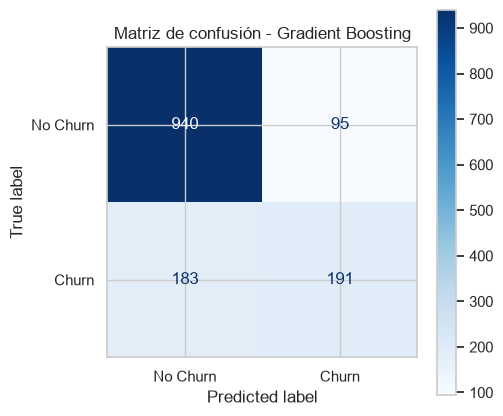

In [34]:
fig, ax = plt.subplots(figsize=(5, 5))
ConfusionMatrixDisplay.from_predictions(
    y_test, y_pred, display_labels=["No Churn", "Churn"], cmap="Blues", ax=ax
)
ax.set_title(f"Matriz de confusión - {mejor_modelo_nombre}")
plt.show()

##### Interpretación de la Gráfica

Cada celda muestra cuántos clientes cayeron en esa combinación de predicción real vs. predicción del modelo, con colores más oscuros para valores más altos. La diagonal principal son los aciertos del modelo, mientras que las otras dos celdas son los errores.

El resultado muestra que el modelo predijo correctamente a 1131 clientes, de los cuáles 191 efectivamente abandonaron el servicio, mientras que los 940 restantes efectivamente se quedaron.

Para los 278 clientes restantes, el modelo predictivo tuvo 183 falsos negativos y 95 falsos positivos.

#### Curva ROC y curva Precision-Recall
Hasta ahora, todas las métricas se calcularon usando un umbral de decisión fijo de 0.5, donde si el modelo calcula que un cliente tiene más de 50% de probabilidad de irse, lo clasifica como "Churn"; si no, como "No Churn". Pero ese 0.5 es una elección arbitraria, no una regla obligatoria. Las curvas ROC y
Precision-Recall muestran cómo cambiaría el desempeño del modelo si se moviera ese umbral, sin necesidad de reentrenar nada.
 
- **Curva ROC:** en el eje horizontal muestra la tasa de falsos positivos, y en el vertical, la tasa de verdaderos positivos (recall), a medida que se recorren distintos umbrales. Entre más se pegue la curva hacia la esquina superior izquierda, mejor distingue el modelo entre ambas clases. El área bajo esta curva es justamente el ROC-AUC ya calculado (~ 0.84).

- **Curva Precision-Recall**: muestra cómo cambian precision y recall entre sí a medida que se mueve el umbral, donde normalmente subir uno implica bajar el otro. En datasets desbalanceados como este, esta curva suele ser más informativa que la ROC, porque la ROC puede verse buena incluso cuando al modelo le cuesta trabajo con la clase minoritaria, mientras que la Precision-Recall refleja ese esfuerzo de forma más directa.

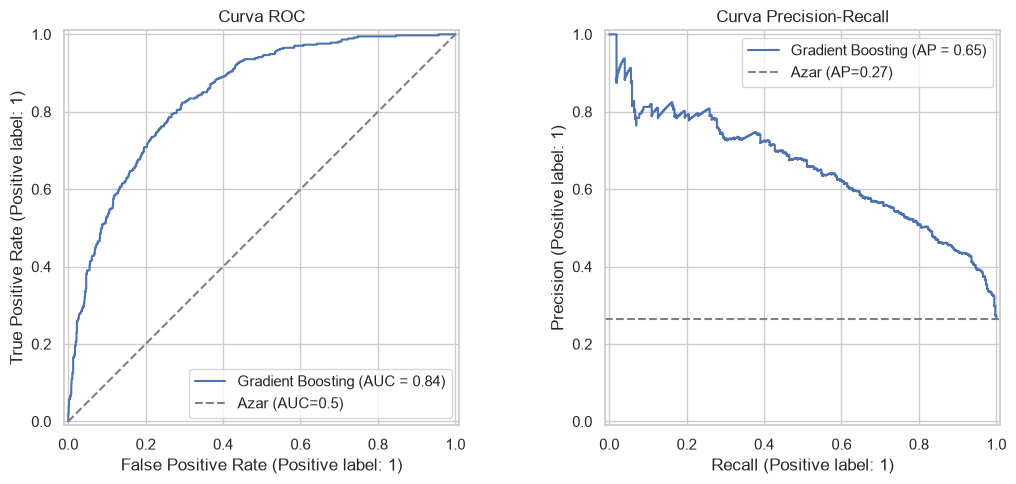

Average Precision (AP): 0.654


In [35]:
fig, axes = plt.subplots(1, 2, figsize=(11, 5))

RocCurveDisplay.from_predictions(y_test, y_proba, ax=axes[0], name=mejor_modelo_nombre)
axes[0].plot([0, 1], [0, 1], linestyle="--", color="gray", label="Azar (AUC=0.5)")
axes[0].set_title("Curva ROC")
axes[0].legend()

PrecisionRecallDisplay.from_predictions(y_test, y_proba, ax=axes[1], name=mejor_modelo_nombre)
tasa_positivos = y_test.mean()
axes[1].axhline(tasa_positivos, linestyle="--", color="gray", label=f"Azar (AP={tasa_positivos:.2f})")
axes[1].set_title("Curva Precision-Recall")
axes[1].legend()

plt.tight_layout()
plt.show()

print("Average Precision (AP):", round(average_precision_score(y_test, y_proba), 3))

##### Interpretación de Ambas Curvas
La curva ROC muestra un despegue claro por encima de la línea diagonal de azar, consistente con el AUC de 0.84 ya calculado.

La curva Precision-Recall parte alta y desciende a medida que se relaja el umbral y el modelo empieza a marcar más casos como riesgo, ganando recall pero perdiendo algo de precisión. El **Average Precision (AP)** de aproximadamente 0.65 resume esa curva en un solo número, y está muy por encima de la línea base de azar (la proporción real de churn ~ 0.27), confirmando que el modelo aporta una capacidad predictiva real.

#### Importancia de Variables
Por último, dentro de la evaluación del modelo, es útil mirar qué variables está usando más el modelo para tomar sus decisiones. Esto sirve como una validación de sentido común, ya que si el modelo le diera mucho peso a variables que no deberían importar para nada, sería una señal de alerta. Si, en cambio, las variables más importantes tienen sentido de negocio, como el tipo de contrato o el tipo de servicio de internet, eso refuerza la confianza en que el modelo aprendió patrones reales y no ruido.

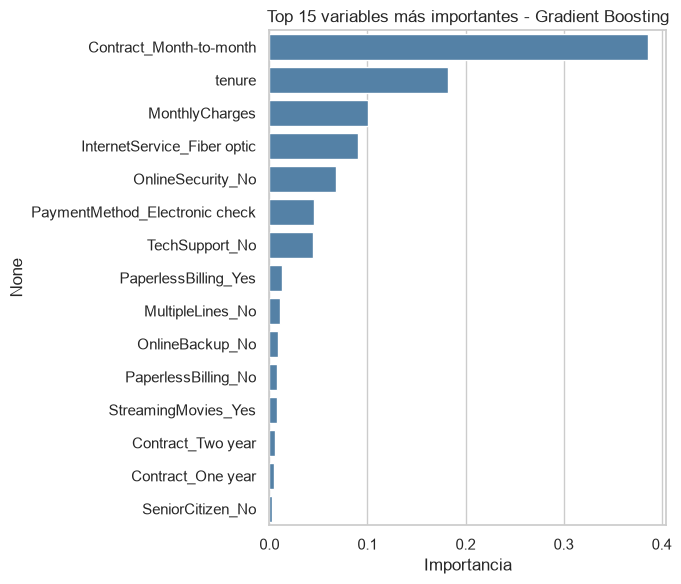

In [36]:
# Los modelos basados en arboles (Random Forest, Gradient Boosting, XGBoost) exponen
#'feature_importances_', mientras que la Regresión Logística expone 'coef_' (sus coeficientes).

if hasattr(modelo_final, "feature_importances_"):
  importancias = pd.Series(modelo_final.feature_importances_, index=X_train.columns)

elif hasattr(modelo_final, "coef_"):
  importancias = pd.Series(np.abs(modelo_final.coef_[0]), index=X_train.columns)

else:
  importancias = None

if importancias is not None:
  top15 = importancias.sort_values(ascending=False).head(15)
  plt.figure(figsize=(7, 6))
  sns.barplot(x=top15.values, y=top15.index, color="steelblue")
  plt.title(f"Top 15 variables más importantes - {mejor_modelo_nombre}")
  plt.xlabel("Importancia")
  plt.tight_layout()
  plt.show()

##### Interpretación de los Resultados
En los primeros puestos se encuentran variables como `Contract_Month-to-month`, que indica que el tipo de contrato es mensual, `tenure`, que representa la antigüedad del cliente, `MonthlyCharges`, que representa el monto que se le cobra al cliente cada mes e `InternetService_Fiber optic` que indica que el tipo de servicio de internet es de fibra óptica. Estas variables son justamente las que se habían señalado como fuertemente relacionadas con el churn durante el análisis exploratorio, lo que indica una buena señal de consistencia en todo el proyecto.

### Análisis de Errores

Antes de realizar la interpretación general de los resultados, vale la pena mirar con más detalle qué tipo de clientes se le escapan al modelo. Para ello se comparan las características promedio de dos grupos: los clientes que sí se fueron y el modelo detectó correctamente (verdaderos positivos), contra los que sí se fueron pero el modelo no detectó (falsos negativos).

In [37]:
df_analisis = X_test.copy()
df_analisis["real"] = y_test.values
df_analisis["prediccion"] = y_pred

verdaderos_positivos = df_analisis[(df_analisis["real"] == 1) & (df_analisis["prediccion"] == 1)]
falsos_negativos = df_analisis[(df_analisis["real"] == 1) & (df_analisis["prediccion"] == 0)]

# Se eligen algunas variables clave para comparar el perfil promedio de ambos grupos
columnas_interes = [
  "tenure", "MonthlyCharges", "Contract_Month-to-month", "Contract_Two year",
  "InternetService_Fiber optic", "OnlineSecurity_Yes", "TechSupport_Yes",
]

comparacion_errores = pd.DataFrame({
  "Detectados correctamente (VP)": verdaderos_positivos[columnas_interes].mean(),
  "No detectados (FN)": falsos_negativos[columnas_interes].mean(),
}).round(3)

print(f"Verdaderos positivos: {len(verdaderos_positivos)} | Falsos negativos: {len(falsos_negativos)}")
comparacion_errores

Verdaderos positivos: 191 | Falsos negativos: 183


,Detectados correctamente (VP),No detectados (FN)
tenure,-1.024,-0.264
MonthlyCharges,0.396,0.118
Contract_Month-to-month,1.000,0.754
Contract_Two year,0.000,0.049
InternetService_Fiber optic,0.832,0.508
OnlineSecurity_Yes,0.058,0.273
TechSupport_Yes,0.037,0.290


#### Detalles a Tener en Cuenta
Para no malinterpretar la tabla se debe tener en cuenta que `tenure` y `MonthlyCharges` fueron estandarizadas durante el preprocesamiento, por lo que un valor negativo significa "por debajo del promedio general de todos los clientes" y uno positivo, "por encima". Las demás columnas son 0/1, así que su promedio se puede leer directamente como "porcentaje de clientes de ese grupo que cumple esa condición".

#### Interpretación de los Resultados
Los clientes correctamente detectados (VP) tienen un perfil de riesgo muy marcado: prácticamente el 100% tiene contrato mes a mes, más del 80% tiene fibra óptica y muy pocos cuentan con seguridad en línea o soporte técnico contratado.

Los falsos negativos, en cambio, tienen un perfil bastante menos marcado: contratos algo más largos, más presencia de servicios adicionales como `OnlineSecurity` y `TechSupport`, y una antigüedad más cercana al promedio general.

Esto indica que el modelo identifica muy bien los casos obvios de riesgo, pero le cuesta más detectar los casos de churn que no siguen ese patrón típico, es decir, clientes que, en apariencia, se ven relativamente estables, pero terminan yéndose de todas formas.

## 8.2. Interpretación de los Resultados


#### ¿El Modelo Mejora al Modelo Base?
Sí, de forma clara y medible. El modelo base `DummyClassifier` con la estrategia `most_frequent` tiene recall y F1-score de **0** para la clase `Churn`, es decir, nunca identifica a ningún cliente en riesgo, aunque su *accuracy* (73.5%) parezca razonable a primera vista.

El modelo predictivo final `Gradient Boosting` alcanza un **F1 ≈ 0.58**, un **recall ≈ 0.51** y un **ROC-AUC ≈ 0.84**. En términos concretos pasa de "no detectar a nadie en riesgo" a "detectar correctamente a más de la mitad de los clientes que efectivamente cancelan el servicio". Esa diferencia es justamente el valor que aporta construir un modelo predictivo en vez de simplemente asumir que ningún cliente se va.

#### ¿La Métrica Obtenida es Razonable?
Sí. Un ROC-AUC de 0.84 se considera un desempeño bueno. Aunque no es espectacular, es sólido para un modelo de churn construido solo con variables estructurales del cliente como el tipo de contrato, servicios contratados, forma de pago, antigüedad, sin datos de comportamiento reciente como contactos al servicio al cliente o quejas registradas, que normalmente ayudarían a mejorar aún más estos números. Los resultados obtenidos no muestran indicios de sobreajuste ni de resultados sospechosamente perfectos, que de haber aparecido, habrían sido más bien una señal de alguna fuga de información pasada por alto.

Un hallazgo que vale la pena mencionar es que el ajuste de hiperparámetros por `GridSearchCV` no logró superar la configuración por defecto del modelo. Esto no invalida el proceso, confirma que, para este dataset, los valores por defecto de scikit-learn ya eran una elección acertada y deja abierta la posibilidad de ampliar la búsqueda en una futura iteración.


#### ¿Cuáles Fueron las Principales Dificultades?
- El desbalance de clases (~ 27% de casos positivos) obligó a elegir con cuidado qué métrica usar como criterio principal: el *accuracy*, que a primera vista parece la métrica más natural, resulta engañoso en este contexto y hubiera llevado a conclusiones equivocadas.

- Existe una tensión natural entre precision (67%) y recall (51%): las curvas ROC y Precision-Recall mostraron que sería posible mover el umbral de decisión para detectar más clientes en riesgo, pero eso aumentaría también las falsas alarmas. El umbral por defecto (0.5) usado en todo este notebook es un punto de partida razonable, pero no necesariamente el más óptimo.

- El análisis de errores reveló que los casos más difíciles de detectar no siguen el patrón "típico" de riesgo (contrato mensual, fibra óptica, sin soporte técnico), lo que pone un límite práctico a qué tan alto puede llegar el recall usando únicamente las variables disponibles en este dataset.

- La búsqueda de hiperparámetros es costosa en tiempo de cómputo, por lo que la grilla de valores probada se mantuvo en un rango razonable para que el notebook pudiera ejecutarse en un computador personal. Esto también implica que no se descarta que exista una mejor combinación fuera de ese rango.

#### ¿Qué Aspectos Podrían Mejorarse en Futuras Versiones?
- Probar técnicas específicas para el desbalance de clases, generando ejemplos sintéticos de la clase minoritaria, siempre ajustándolo únicamente sobre el conjunto de entrenamiento, para no introducir fuga de información hacia el conjunto de prueba.

- Ajustar el umbral de decisión de forma deliberada en vez de dejarlo fijo en 0.5, según el costo real que tenga para el negocio un falso negativo (perder un cliente sin haberlo detectado) frente a un falso positivo (invertir esfuerzo de retención en alguien que de todas formas no se iba a ir).

- Explorar combinaciones entre variables (por ejemplo, tipo de contrato junto con método de pago), que en la exploración de datos ya habían mostrado relación con el churn por separado.


## 9.2. Garantía de Reproducibilidad

En concordancia con los lineamientos del curso, este notebook fue diseñado para ejecutarse de principio a fin de manera autónoma, desatendida y reproducible (*Run All*), garantizando que cualquier evaluador obtenga exactamente los mismos resultados numéricos y gráficos:

* **Semilla Aleatoria Global (`RANDOM_STATE = 42`):** Se definió de forma centralizada al inicio del notebook y se propagó explícitamente en todas las funciones estocásticas:
  * Partición de datos: `train_test_split(..., random_state=42)`
  * Esquema de validación: `StratifiedKFold(..., random_state=42)`
  * Clasificador base: `DummyClassifier(..., random_state=42)`
  * Modelos candidatos: `LogisticRegression`, `RandomForestClassifier`, `GradientBoostingClassifier` y `XGBClassifier`
  * Optimización: `GridSearchCV`
* **Ejecución Lineal y Secuencial:** El flujo de celdas sigue un orden lógico estricto:  

  Carga --> EDA --> Preprocesamiento --> Partición sin fuga --> Baseline --> Validación Cruzada --> Evaluación en Test --> Serialización.  

  No existen referencias a variables creadas en celdas posteriores ni dependencias de ejecución manual desordenada.
* **Carga Resiliente de Datos (Local y Nube):** La celda de carga de datos incorpora un bloque `try-except` que detecta si el archivo `DatosCrudos.csv` existe localmente; de no encontrarlo, descarga automáticamente el dataset original desde el repositorio remoto de GitHub sin requerir intervención manual del usuario.
* **Entorno y Dependencias Documentadas:** Todas las librerías necesarias con sus versiones compatibles están declaradas formalmente en el archivo `requirements.txt` y justificadas conceptualmente en la sección de configuración inicial del notebook.


# 10. Almacenamiento del Modelo

Al finalizar el entrenamiento y la evaluación, el modelo predictivo debe almacenarse en disco para que pueda ser reutilizado en fases posteriores (despliegue en API o aplicaciones interactivas).

En esta sección se demuestra que el modelo puede:
1. **Entrenarse** (completado anteriormente con `modelo_final`).
2. **Guardarse correctamente en disco** utilizando `joblib`.
3. **Cargarse nuevamente** desde el archivo almacenado.
4. **Generar predicciones idénticas** con el modelo recuperado.


In [38]:
# 1. Guardar el modelo en disco con joblib
ruta_archivo = 'modelo_churn.joblib'
joblib.dump(modelo_final, ruta_archivo)
print(f"Modelo guardado exitosamente en: {ruta_archivo}")

# 2. Cargar nuevamente el modelo desde disco
modelo_recuperado = joblib.load(ruta_archivo)
print(f"Modelo cargado desde disco: {type(modelo_recuperado).__name__}")

# 3. Generar predicciones utilizando el modelo almacenado
y_pred_recuperado = modelo_recuperado.predict(X_test)

# 4. Comprobar que las predicciones coincidan exactamente con las originales
coincidencia_exacta = np.array_equal(y_pred, y_pred_recuperado)
print(f"¿Las predicciones coinciden al 100%?: {coincidencia_exacta}")
assert coincidencia_exacta, '¡Error! Las predicciones del modelo cargado difieren de las originales.'


Modelo guardado exitosamente en: modelo_churn.joblib
Modelo cargado desde disco: GradientBoostingClassifier
¿Las predicciones coinciden al 100%?: True


### Conclusión del Almacenamiento
Se verificó con éxito que el archivo `modelo_churn.joblib` contiene el estimador completamente entrenado y reproduce con exactitud todas las predicciones sobre el conjunto de prueba, cumpliendo con la totalidad de los requisitos de la fase de modelado.
